# **Credit Risk Prediction Using Machine Learning: An Intelligent Agent Approach**

Dataset Link - https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

**Agent** - The agent is the decision-making entity that uses the ML model to classify credit applicants.
Logistic Regression or Decision Tree classifier acts as the agent.

**Environment** - The environment is the context in which the agent operates
The German Credit dataset represents the environment.



**Objectives** -
Accurately classify applicants as Good (repayment likely) or Bad (risk of default).
Maximize overall predictive performance using metrics like Accuracy, F1-score, ROC-AUC.

# **Loading Dataset**

In [1]:
import pandas as pd

german_df = pd.read_csv("/content/german.data-numeric", sep=r"\s+", header=None)

german_df.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,1,6,4,12,5,5,3,4,1,67,...,0,0,1,0,0,1,0,0,1,1
1,2,48,2,60,1,3,2,2,1,22,...,0,0,1,0,0,1,0,0,1,2
2,4,12,4,21,1,4,3,3,1,49,...,0,0,1,0,0,1,0,1,0,1
3,1,42,2,79,1,4,3,4,2,45,...,0,0,0,0,0,0,0,0,1,1
4,1,24,3,49,1,3,3,4,4,53,...,1,0,1,0,0,0,0,0,1,2


In [2]:
german_df.shape

(1000, 25)

# **Data-Cleaning**

### **Adding Feature Names to data**

In [3]:
columns = [f"Attribute_{i}" for i in range(1, 25)] + ["Target"]
german_df.columns = columns

In [4]:
german_df.head()

,Attribute_1,Attribute_2,Attribute_3,Attribute_4,Attribute_5,Attribute_6,Attribute_7,Attribute_8,Attribute_9,Attribute_10,...,Attribute_16,Attribute_17,Attribute_18,Attribute_19,Attribute_20,Attribute_21,Attribute_22,Attribute_23,Attribute_24,Target
0,1,6,4,12,5,5,3,4,1,67,...,0,0,1,0,0,1,0,0,1,1
1,2,48,2,60,1,3,2,2,1,22,...,0,0,1,0,0,1,0,0,1,2
2,4,12,4,21,1,4,3,3,1,49,...,0,0,1,0,0,1,0,1,0,1
3,1,42,2,79,1,4,3,4,2,45,...,0,0,0,0,0,0,0,0,1,1
4,1,24,3,49,1,3,3,4,4,53,...,1,0,1,0,0,0,0,0,1,2


### **Check for Missing Values**

In [5]:
german_df.isnull().sum()

,0
Attribute_1,0
Attribute_2,0
Attribute_3,0
Attribute_4,0
Attribute_5,0
Attribute_6,0
Attribute_7,0
Attribute_8,0
Attribute_9,0
Attribute_10,0


### **Check number of duplicate rows**

In [6]:
duplicates = german_df.duplicated()
print("Duplicate rows:", duplicates.sum())

Duplicate rows: 0


# **EDA**

### **Quick overview of the Dataset**

In [7]:
german_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Attribute_1   1000 non-null   int64
 1   Attribute_2   1000 non-null   int64
 2   Attribute_3   1000 non-null   int64
 3   Attribute_4   1000 non-null   int64
 4   Attribute_5   1000 non-null   int64
 5   Attribute_6   1000 non-null   int64
 6   Attribute_7   1000 non-null   int64
 7   Attribute_8   1000 non-null   int64
 8   Attribute_9   1000 non-null   int64
 9   Attribute_10  1000 non-null   int64
 10  Attribute_11  1000 non-null   int64
 11  Attribute_12  1000 non-null   int64
 12  Attribute_13  1000 non-null   int64
 13  Attribute_14  1000 non-null   int64
 14  Attribute_15  1000 non-null   int64
 15  Attribute_16  1000 non-null   int64
 16  Attribute_17  1000 non-null   int64
 17  Attribute_18  1000 non-null   int64
 18  Attribute_19  1000 non-null   int64
 19  Attribute_20  1000 non-null 

In [8]:
german_df.describe()

,Attribute_1,Attribute_2,Attribute_3,Attribute_4,Attribute_5,Attribute_6,Attribute_7,Attribute_8,Attribute_9,Attribute_10,...,Attribute_16,Attribute_17,Attribute_18,Attribute_19,Attribute_20,Attribute_21,Attribute_22,Attribute_23,Attribute_24,Target
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000
mean,2.577000,20.903000,2.54500,32.711000,2.105000,3.384000,2.68200,2.845000,2.358000,35.546000,...,0.234000,0.103000,0.907000,0.041000,0.179000,0.713000,0.022000,0.2000,0.630000,1.300000
std,1.257638,12.058814,1.08312,28.252605,1.580023,1.208306,0.70808,1.103718,1.050209,11.375469,...,0.423584,0.304111,0.290578,0.198389,0.383544,0.452588,0.146757,0.4002,0.483046,0.458487
min,1.000000,4.000000,0.00000,2.000000,1.000000,1.000000,1.00000,1.000000,1.000000,19.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,1.000000
25%,1.000000,12.000000,2.00000,14.000000,1.000000,3.000000,2.00000,2.000000,1.000000,27.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,1.000000
50%,2.000000,18.000000,2.00000,23.000000,1.000000,3.000000,3.00000,3.000000,2.000000,33.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.0000,1.000000,1.000000
75%,4.000000,24.000000,4.00000,40.000000,3.000000,5.000000,3.00000,4.000000,3.000000,42.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.0000,1.000000,2.000000
max,4.000000,72.000000,4.00000,184.000000,5.000000,5.000000,4.00000,4.000000,4.000000,75.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0000,1.000000,2.000000


In [9]:
german_df["Target"] = german_df["Target"].apply(lambda x: 1 if x == 2 else 0) # converting target variable into binary

In [10]:
german_df['Target'].head()

,Target
0,0
1,1
2,0
3,0
4,1


In [11]:
german_df["Target"].value_counts()

,count
Target,
0,700
1,300


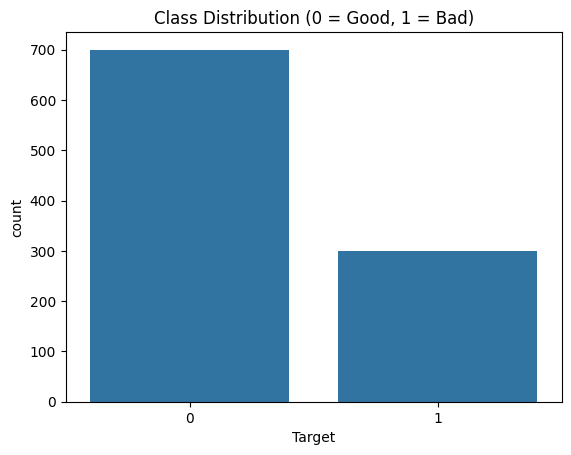

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Target", data=german_df)
plt.title("Class Distribution (0 = Good, 1 = Bad)")
plt.show()

## **Selecting Dependent and Independent Variables**

In [13]:
X = german_df.drop("Target", axis=1)
y = german_df["Target"]

## **Train & Test Split**

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## **Feature Scaling or Normalisation**

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# **Model Building**

## **Logistic Regressor Agent**

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear']
}

# Logistic Regression model
lr = LogisticRegression(max_iter=1000)

# Grid Search for best parameters
grid_lr = GridSearchCV(lr, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_lr.fit(X_train, y_train)

# Best model
best_lr = grid_lr.best_estimator_

print("Best Parameters:", grid_lr.best_params_)


Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}


In [17]:
# Predictions
best_lr.fit(X_train, y_train)
y_pred_lr = best_lr.predict(X_test)

In [18]:
import numpy as np
# Accuracy
accuracy = accuracy_score(y_test, y_pred_lr)

# F1-score
f1 = f1_score(y_test, y_pred_lr)

# Precision & Recall
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)

# Predict probabilities for ROC-AUC
y_prob_lr = best_lr.predict_proba(X_test)[:, 1]

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob_lr)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)

# Print all metrics
print("Logistic Regression Metrics")
print("---------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Logistic Regression Metrics
---------------------------
Accuracy : 0.7650
F1-score : 0.5524
Precision: 0.6304
Recall   : 0.4915
ROC-AUC  : 0.7962


In [19]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       141
           1       0.63      0.49      0.55        59

    accuracy                           0.77       200
   macro avg       0.72      0.69      0.70       200
weighted avg       0.75      0.77      0.76       200



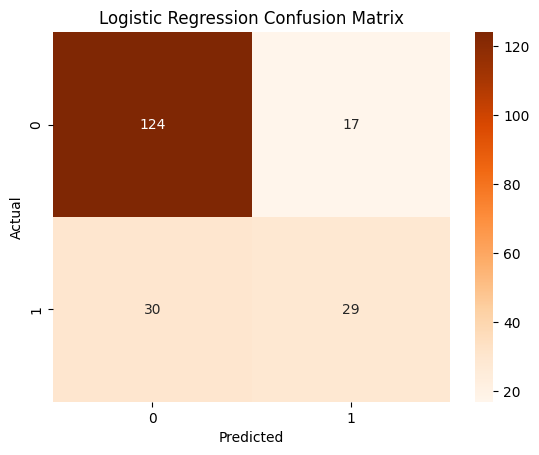

In [20]:
# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Oranges")

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

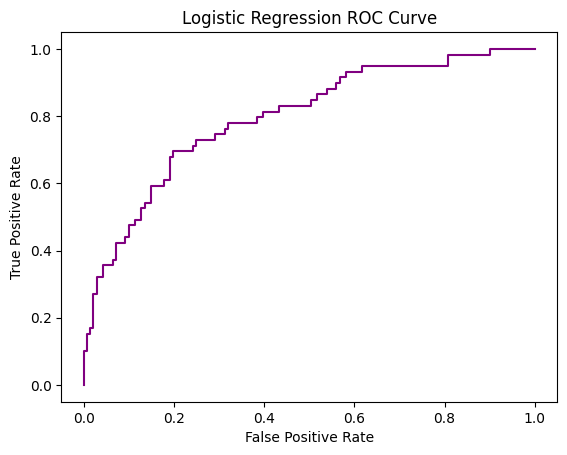

ROC-AUC: 0.7962495492246664


In [21]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
plt.plot(fpr, tpr, color='purple')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve")
plt.show()

print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

## **Decision Tree Classifier Agent**

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Parameter grid for tuning
param_grid = {
    'max_depth': [3, 5, 10, 15, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Base model
dt = DecisionTreeClassifier(random_state=42)

# Grid Search with Cross Validation
grid_dt = GridSearchCV(
    dt,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

# Best model
best_dt = grid_dt.best_estimator_

print("Best Parameters:", grid_dt.best_params_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5}


In [24]:
# Predictions
best_dt.fit(X_train, y_train)
y_pred_dt = best_dt.predict(X_test)

In [25]:
# Accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

# F1-score
f1_dt = f1_score(y_test, y_pred_dt)

# Precision & Recall
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)

# Predict probabilities for ROC-AUC
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

# ROC-AUC
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Print all metrics
print("Decision Tree Metrics")
print("--------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"F1-score : {f1_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"ROC-AUC  : {roc_auc_dt:.4f}")

Decision Tree Metrics
--------------------
Accuracy : 0.6950
F1-score : 0.4505
Precision: 0.4808
Recall   : 0.4237
ROC-AUC  : 0.6652


In [26]:
print("\nClassification Report for Decision Tree:")
print(classification_report(y_test, y_pred_dt))


Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.77      0.81      0.79       141
           1       0.48      0.42      0.45        59

    accuracy                           0.69       200
   macro avg       0.63      0.62      0.62       200
weighted avg       0.68      0.69      0.69       200



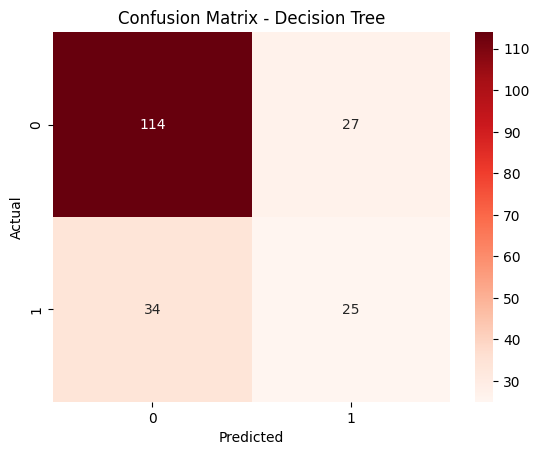

In [27]:
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Reds")
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

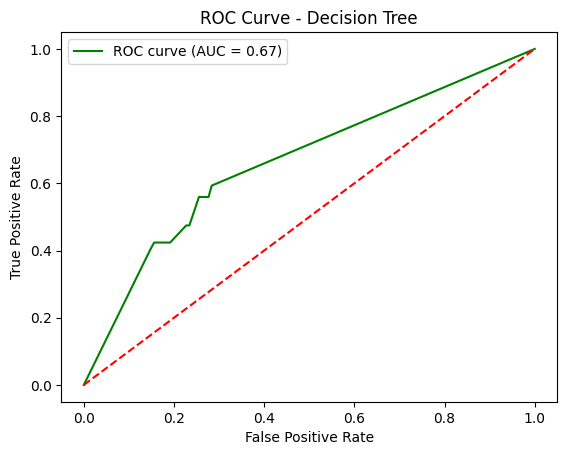

In [28]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt)

plt.plot(fpr_dt, tpr_dt, label=f"ROC curve (AUC = {roc_auc_dt:.2f})", color='green')
plt.plot([0,1], [0,1], linestyle='--', color='red')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

# **Comparison of Results**

In [29]:
import pandas as pd

# Metrics only
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_dt)],
    "F1-Score": [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_dt)],
    "Precision": [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_dt)],
    "Recall": [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_dt)],
    "ROC-AUC": [roc_auc_score(y_test, y_prob_lr), roc_auc_score(y_test, y_prob_dt)]
})

comparison

,Model,Accuracy,F1-Score,Precision,Recall,ROC-AUC
0,Logistic Regression,0.765,0.552381,0.630435,0.491525,0.796250
1,Decision Tree,0.695,0.450450,0.480769,0.423729,0.665164


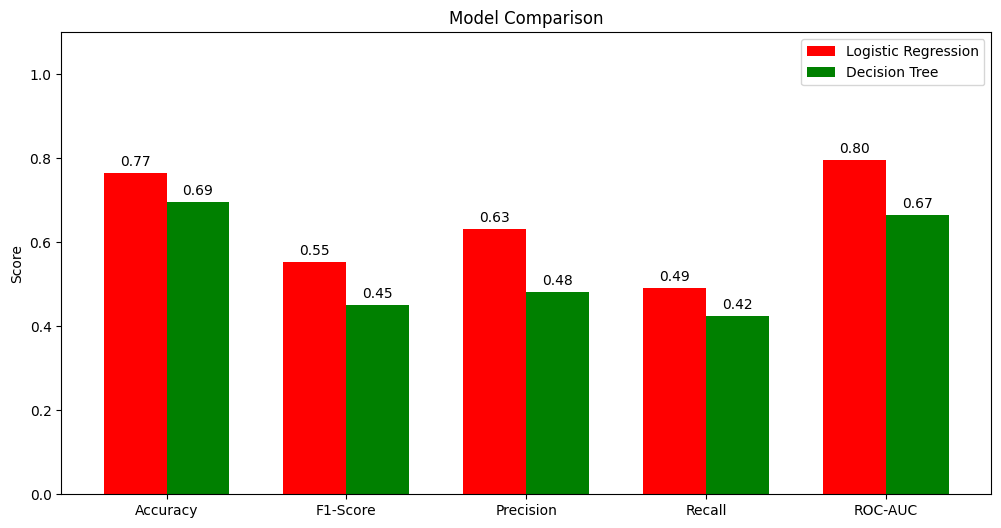

In [30]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "F1-Score", "Precision", "Recall", "ROC-AUC"]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, comparison.loc[0, metrics], width,
                label='Logistic Regression', color='red')

bars2 = plt.bar(x + width/2, comparison.loc[1, metrics], width,
                label='Decision Tree', color='green')

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Model Comparison")
plt.legend()

# Add values on top of bars
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01,
             f"{yval:.2f}", ha='center', va='bottom')

for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01,
             f"{yval:.2f}", ha='center', va='bottom')

plt.ylim(0, 1.1)
plt.show()